**PNV3421 - Exercício 2 de ARIMA**

In [ ]:
# ===============================
# 1. IMPORTAÇÃO E CARREGAMENTO
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Desligar alguns warnings
import warnings
from statsmodels.tools.sm_exceptions import ValueWarning
warnings.simplefilter("ignore", ValueWarning)
warnings.filterwarnings("ignore") # novo

# Biblioteca para permitir a leitura do Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Carregar dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Exercício2.txt",
                 delimiter=" ", decimal=",")
df.reset_index(drop=True, inplace=True)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Yt
0,222.34
1,222.24
2,221.17
3,218.88
4,220.05


In [ ]:
# ===============================
# 2. IDENTIFICANDO MODELO ÓTIMO PELO BOX JENKINS
# ===============================

P = range(0, 4)
D = range(0, 4)
Q = range(0, 4)

melhor_aic = float("inf")
melhor_bic = float("inf")
melhor_ordem_aic = None
melhor_ordem_bic = None
melhor_modelo_aic = None
melhor_modelo_bic = None

for p in P:
    for d in D:
        for q in Q:
            try:
                modelo = ARIMA(df, order=(p, d, q)).fit()
                aic = modelo.aic
                bic = modelo.bic
                if aic < melhor_aic:
                    melhor_aic = aic
                    melhor_ordem_aic = (p, d, q)
                    melhor_modelo_aic = modelo
                if bic < melhor_bic:
                    melhor_bic = bic
                    melhor_ordem_bic = (p, d, q)
                    melhor_modelo_bic = modelo
            except:
                pass

print("Melhor modelo por AIC:", melhor_ordem_aic, " | AIC:", melhor_aic)
print("Melhor modelo por BIC:", melhor_ordem_bic, " | BIC:", melhor_bic)

if melhor_ordem_aic != melhor_ordem_bic:
    print("Aviso: o modelo ótimo pelo AIC não coincide com o ótimo pelo BIC.")
    print("\nResumo do modelo escolhido pelo AIC:")
    print(melhor_modelo_aic.summary())
    print("\nResumo do modelo escolhido pelo BIC:")
    print(melhor_modelo_bic.summary())
else:
    print("O melhor modelo é o mesmo para AIC e BIC.")
    print("\nResumo do melhor modelo:")
    print(melhor_modelo_bic.summary())

Melhor modelo por AIC: (0, 2, 1)  | AIC: 262.3879145993912
Melhor modelo por BIC: (0, 2, 1)  | BIC: 266.67418405217427
O melhor modelo é o mesmo para AIC e BIC.

Resumo do melhor modelo:
                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   65
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -129.194
Date:                Thu, 27 Nov 2025   AIC                            262.388
Time:                        18:04:43   BIC                            266.674
Sample:                             0   HQIC                           264.074
                                 - 65                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7902  

In [ ]:
# ===============================
# 3. VERIFICANDO COM O AUTO-ARIMA
# ===============================

!pip install pmdarima
import pmdarima as pm

model = pm.auto_arima(
    df,
    #seasonal=True,
    #m=12,                   # se mensal
    stepwise=True,           # rápido e estável
    trace=True,              # mostra a busca (estilo Box-Jenkins)
    error_action='ignore',
    suppress_warnings=True
)

print(model.summary())

model = pm.auto_arima(
    df,
    #seasonal=True,
    #m=12,                   # se mensal
    stepwise=True,           # rápido e estável
    trace=True,              # mostra a busca (estilo Box-Jenkins)
    error_action='ignore',
    suppress_warnings=True,
    d=2                      # forçando d=2
)

print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=269.367, Time=0.17 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=269.313, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=265.830, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=265.856, Time=0.03 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=283.592, Time=0.01 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=267.830, Time=0.04 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=266.742, Time=0.12 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=269.573, Time=0.11 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=271.542, Time=0.02 sec

Best model:  ARIMA(1,1,0)(0,0,0)[0] intercept
Total fit time: 0.554 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   65
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -129.915
Date:                Thu, 27 Nov 2025   AIC               

O auto_arima com os parâmetros da aula não encontra o d=2. Lendo a documentação, vi que ele tem um otimizador interno, e certamente está caindo em um mínimo local em (1,1,0). Forçando d=2, ele nos confirma que (0,2,1) é o mínimo global.


==== ARIMA("ótimo") ====

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   65
Model:                 ARIMA(0, 2, 1)   Log Likelihood                -129.194
Date:                Thu, 27 Nov 2025   AIC                            262.388
Time:                        18:27:32   BIC                            266.674
Sample:                             0   HQIC                           264.074
                                 - 65                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7902      0.093     -8.461      0.000      -0.973      -0.607
sigma2         3.4833      0.767      4.540      0.000       1.980       4.987
Ljung-Box (L1) (Q):      

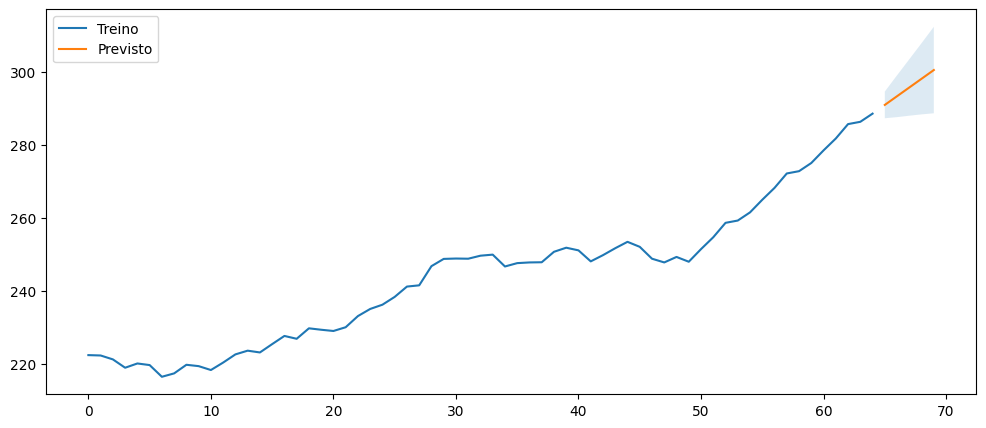

In [ ]:
# ===============================
# 4. PLOTANDO ARIMA ÓTIMO NAS PRÓXIMAS 5 MEDIÇÕES (PREVISÃO PARA AS PRÓXIMAS 5 MEDIÇÕES)
# ===============================
print("\n==== ARIMA(\"ótimo\") ====\n")
model = ARIMA(df, order=melhor_ordem_aic) # acabamos de checar com o auto
fitted = model.fit()
print(fitted.summary())

pred = fitted.get_forecast(steps=5)
fc = pred.predicted_mean
conf = pred.conf_int()

n = len(df)

fc_series = pd.Series(fc, index=range(n,n+5))
lower = pd.Series(conf.iloc[:,0], index=range(n,n+5))
upper = pd.Series(conf.iloc[:,1], index=range(n,n+5))

plt.figure(figsize=(12,5))
plt.plot(df, label="Treino")
plt.plot(fc_series, label="Previsto")
plt.fill_between(range(n,n+5), lower, upper, alpha=.15)
plt.legend()
plt.show()